<a href="https://colab.research.google.com/github/vitor-thompson/physics-informed-neural-networks-pinn/blob/main/experiments/passo-01-resfriamento-newton/passo_01_resfriamento_newton.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PINN — Experimento 01: Resfriamento de Newton com PyTorch**


## __Tabela de conteúdos__

<ol>
    <li><a href="#Objectives">Objetivos</a></li>
    <li>
        <a href="#Setup">Configuração</a>
        <ol>
            <li><a href="#Installing-Required-Libraries">Instalação das Bibliotecas Necessárias</a></li>
            <li><a href="#Importing-Required-Libraries">Importação das Bibliotecas Necessárias</a></li>
            <li><a href="#Device-Check-for-PyTorch">Verificação de Dispositivo para PyTorch</a></li>
        </ol>
    </li>
    <li>
        <a href="#Background">Contexto Teórico</a>
        <ol>
            <li><a href="#Physics-Informed-Neural-Networks-(PINNs)-Theory">Teoria das Redes Neurais Informadas por Física (PINNs)</a></li>
            <li><a href="#Thermal/Chemical-Diffusion-Theory-&amp;-Numerical-Solution">Lei do Resfriamento de Newton & Solução Analítica/Numérica</a></li>
            <li><a href="#Why-PINNs?">Por que PINNs?</a></li>
        </ol>
    </li>
    <li>
        <a href="#The-Model">O Modelo</a>
        <ol>
            <li><a href="#The-Neural-Network">A Rede Neural</a></li>
            <li><a href="#The-Loss-Function">A Função de Perda Física (Loss)</a></li>
            <li><a href="#Training">Treinamento</a></li>
        </ol>
    </li>
    <li>
        <a href="#Result">Resultado</a>
        <ol>
            <li><a href="#Comparing-to-Theoretical-Solution">Comparação com a Solução Teórica</a></li>
            <li><a href="#Visualizing-Training-Convergence">Visualização da Convergência do Treinamento</a></li>
        </ol>
    </li>
</ol>

## Objetivos

Após a conclusão deste laboratório, você será capaz de:

- Compreender a teoria por trás das Redes Neurais Informadas por Física (PINNs).
- Construir e implementar uma PINN usando PyTorch para modelar a Lei do Resfriamento de Newton.
- Calcular derivadas temporais com diferenciação automática e incluir a equação diferencial na função de perda (*loss*) para resolver uma EDO de 1ª ordem.
- Comparar a previsão da rede neural com a solução teórica e acompanhar a convergência do treinamento.

----


## Configuração

Para este laboratório, você usará as seguintes bibliotecas:

*   [`numpy`](https://numpy.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) para operações matemáticas.
*   [`PyTorch`](https://pytorch.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) para aprendizado de máquina e funções relacionadas a pipelines de deep learning.
*   [`scipy`](https://seaborn.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) para calcular a solução pelo método numérico tradicional.
*   [`matplotlib`](https://matplotlib.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) para ferramentas adicionais de plotagem gráfica.

### Instalação das bibliotecas necessárias

Antes de começarmos a construir nossa Rede Neural Informada por Física (PINN), precisamos garantir que todas as bibliotecas necessárias estejam instaladas. Esta etapa configurará o ambiente necessário para o laboratório, incluindo o `PyTorch` e outros pacotes essenciais.

In [1]:
%pip install torch numpy matplotlib scipy

Execute o comando acima para instalar as bibliotecas necessárias. **A instalação pode levar cerca de 5 minutos**, por favor, seja paciente.

Após executar o comando acima, **reinicie o ambiente de execução (kernel)** para garantir que as bibliotecas sejam carregadas corretamente. Isso ajudará a evitar problemas quando começarmos a programar.

Assim que a instalação for concluída, prosseguiremos para a próxima etapa.

### Importação das bibliotecas necessárias

_Recomendamos que você importe todas as bibliotecas necessárias em um único lugar (aqui):_

In [2]:
from tqdm import tqdm
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
from scipy.special import erf

# You can also use this section to suppress warnings generated by your code:
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn
warnings.filterwarnings('ignore')

### Verificação de dispositivo para PyTorch

O `PyTorch` pode ser acelerado por GPU. Se você tiver uma GPU disponível em seu dispositivo local, você pode baixar este notebook e usar a GPU localmente.

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## Contexto Teórico

### Teoria das Redes Neurais Informadas por Física (PINNs)

As Redes Neurais Informadas por Física (PINNs) são uma abordagem inovadora que mescla as redes neurais tradicionais com princípios físicos para resolver problemas complexos.

O [Artigo científico sobre PINN](https://www.sciencedirect.com/science/article/abs/pii/S0021999118307125) foi publicado no *Journal of Computational Physics* em 2019.

Diferente das redes neurais convencionais que dependem exclusivamente de dados, **as PINNs incorporam as leis físicas subjacentes, como leis de conservação, condições de contorno e equações diferenciais, diretamente no processo de aprendizado**. Essa integração permite que o modelo seja mais preciso, confiável e interpretável, especialmente quando os dados são escassos ou ruidosos.

Em uma PINN, **a função de perda é aumentada com termos que representam os resíduos das equações diferenciais governantes**. Ao minimizar essa função de perda, a rede neural não apenas se ajusta aos dados, mas também satisfaz as leis físicas. Isso torna as PINNs particularmente poderosas para resolver problemas onde as equações governantes são bem conhecidas, como dinâmica de fluidos, transferência de calor e deformação de materiais.

### Lei do Resfriamento de Newton & Solução Teórica

A Lei do Resfriamento de Newton é uma equação diferencial ordinária (EDO) de 1ª ordem que descreve como a temperatura de um corpo varia ao longo do tempo em contato com um ambiente a temperatura constante. A equação é expressa como:

$$
\frac{dT(t)}{dt} = -k\left(T(t) - T_{\text{amb}}\right)
$$

$T(t)$ é a temperatura do corpo no instante de tempo $t$.
- $T_{\text{amb}}$ é a temperatura do ambiente ao redor.
- $k$ é a constante de resfriamento (taxa de decaimento térmico), que depende das propriedades do corpo e do meio.

Neste laboratório, focamos em treinar uma PINN para aprender $T(t)$ respeitando a EDO e a condição inicial, comparando a previsão da rede com a solução teórica exata. Métodos numéricos tradicionais, como o método de Euler ou Runge-Kutta, resolvem essa equação discretizando o tempo em passos pequenos e avançando passo a passo, enquanto a PINN aproxima $T(t)$ como uma função contínua diferenciável por toda a rede neural.

## Por que PINNs?

Embora os métodos numéricos tradicionais sejam eficazes para resolver EDPs, eles podem se tornar computacionalmente caros, **especialmente para problemas de alta dimensão ou geometrias complexas**. Além disso, esses métodos podem exigir um refinamento extensivo de malha e técnicas de estabilização para alcançar soluções precisas.

As Redes Neurais Informadas por Física oferecem uma alternativa poderosa ao incorporar as leis físicas diretamente na arquitetura da rede neural. **As PINNs podem lidar eficientemente com problemas que possuem condições de contorno complexas e domínios irregulares sem a necessidade de malhas extensivas ou discretização**. Além disso, elas podem ser **treinadas usando uma quantidade relativamente pequena de dados**, pois as leis físicas guiam o processo de aprendizado, garantindo que a solução seja fisicamente consistente e orientada por dados.

Ao usar PINNs para resolver a equação de difusão 1D, você obterá uma visão sobre como essa abordagem pode oferecer vantagens sobre os métodos tradicionais, particularmente em termos de flexibilidade, escalabilidade e capacidade de generalização para cenários mais complexos.

## O Modelo

### A Rede Neural
O núcleo da nossa Rede Neural Informada por Física (PINN) é uma rede neural feed-forward totalmente conectada que mapeia a variável de entrada (o tempo $t$) para a grandeza física prevista (a temperatura $T(t)$).

Nesta implementação, a classe `PINNResfriamento` define a arquitetura da rede neural:
- **Entrada:** A rede recebe **1 entrada** contínua, o instante de tempo $t$.
- **Camadas ocultas:** Camadas densas (totalmente conectadas) com função de ativação **Tanh** (muito usada em PINNs porque a `Tanh` é suave e infinitamente diferenciável, o que ajuda no cálculo de derivadas com `autograd`). Para um problema de 1ª ordem como o resfriamento de Newton, 2 a 4 camadas ocultas com cerca de 20 a 50 neurônios já costumam ser suficientes.
- **Saída:** A camada de saída final tem **1 neurônio**, representando a temperatura prevista $T_{\text{pred}}(t)$.

Esse formato trata a temperatura como uma função contínua do tempo $t$, permitindo calcular $\frac{dT}{dt}$ diretamente pela rede. Você pode ajustar o número de camadas, a quantidade de neurônios ou a função de ativação conforme a complexidade do sistema físico.

In [4]:
class PINNResfriamento(nn.Module):
    def __init__(self):
        super(PINNResfriamento, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 50),
            nn.Tanh(),
            nn.Linear(50, 50),
            nn.Tanh(),
            nn.Linear(50, 50),
            nn.Tanh(),
            nn.Linear(50, 50),
            nn.Tanh(),
            nn.Linear(50, 1)
        )

    def forward(self, t):
        return self.net(t)

### A Função de Perda (Loss)
Usando como exemplo a constante de resfriamento $k = 0{,}1$ e temperatura ambiente $T_{\text{amb}} = 25\,^\circ\text{C}$.

A função de perda é fundamental no treinamento de uma PINN, pois guia a rede para que a curva prevista $T(t)$ obedeça tanto à lei física quanto ao estado inicial conhecido do sistema. Como o Resfriamento de Newton é uma EDO apenas no tempo $t$ (sem espaço $x$), não temos condições de contorno espaciais — em vez disso, a perda se apoia em dois componentes principais (e, opcionalmente, pontos de medição/dados):

- **Perda da EDO (ODE Loss):** É o componente físico principal, garantindo que a saída da rede satisfaça $\frac{dT}{dt} = -k(T - T_{\text{amb}})$. Calculamos a derivada temporal $\frac{dT}{dt}$ com diferenciação automática (`torch.autograd.grad`), definimos o resíduo como:
  $$r(t) = \frac{dT}{dt} + k\left(T(t) - T_{\text{amb}}\right)$$
  e tomamos o erro quadrático médio (MSE) desse resíduo, $\text{MSE}(r(t))$. Quando o resíduo vai a zero, a equação física é satisfeita.
- **Perda da Condição Inicial (Initial Condition Loss):** Garante que a rede comece na temperatura certa em $t = 0$, comparando $T(t=0)$ previsto pela rede com a temperatura inicial conhecida $T_0$ por meio do erro quadrático médio $\text{MSE}(T(0) - T_0)$.
- **Perda de Dados (Data Loss — opcional):** Caso você tenha alguns pontos medidos ao longo do tempo, pode adicionar o erro quadrático médio entre a previsão da rede e esses valores observados.

A perda total é a soma desses termos (podendo incluir pesos para equilibrar cada parcela), fazendo com que a rede aprenda uma trajetória térmica fisicamente coerente do início ao fim do intervalo.

In [5]:
def pinn_loss(model, t_colloc, t_0, T_0, k=0.1, T_amb=25.0):
    # 1. Garante que t_colloc exige gradiente para calcular dT/dt
    t_colloc = t_colloc.clone().detach().requires_grad_(True)
    T_pred = model(t_colloc)

    # Derivada temporal dT/dt via diferenciação automática
    dT_dt = torch.autograd.grad(
        T_pred,
        t_colloc,
        grad_outputs=torch.ones_like(T_pred),
        create_graph=True
    )[0]

    # Resíduo da Lei do Resfriamento de Newton: dT/dt + k*(T - T_amb) = 0
    ode_residual = dT_dt + k * (T_pred - T_amb)
    ode_loss = torch.mean(ode_residual ** 2)

    # 2. Perda da condição inicial em t = 0: T(0) = T_0
    T_0_pred = model(t_0)
    ic_loss = torch.mean((T_0_pred - T_0) ** 2)

    return ode_loss + ic_loss

### Treinamento
O processo de treinamento consiste em otimizar iterativamente os pesos da rede neural para minimizar a função de perda total, fazendo com que a temperatura prevista $T(t)$ obedeça à EDO do resfriamento e à condição inicial. O loop de treinamento segue estas etapas:

- **Preparação dos Pontos Temporais:** Geramos os instantes de tempo $t$ no intervalo desejado (por exemplo, de $0$ até $30$ usando `torch.linspace` e reformatando para o formato `(N, 1)`), além do ponto inicial $t_0 = 0$ com a temperatura inicial $T_0$.
- **Zerar Gradientes e Calcular a Perda (`Loss Calculation`):** Em cada época, zeramos os gradientes acumulados do otimizador (`optimizer.zero_grad()`) e chamamos `pinn_loss`, que avalia a rede, calcula $\frac{dT}{dt}$ via `autograd` e soma a perda da EDO com a perda da condição inicial.
- **Retropropagação e Atualização dos Pesos (`Backward Pass and Optimization`):** Chamamos `loss.backward()` para calcular os gradientes em relação aos parâmetros da rede e `optimizer.step()` para atualizar os pesos (por exemplo, com o otimizador `Adam`).
- **Acompanhamento e Salvamento:** Registramos o valor da *loss* ao longo das épocas para acompanhar a convergência e podemos salvar os pesos do modelo (`torch.save(model.state_dict(), ...)`) ao final ou nos melhores momentos.

In [6]:
from tqdm import tqdm


def train(model, optimizer, epochs, t_max=30.0, T_0=100.0, k=0.1, T_amb=25.0):
    saved_models = {}
    epoch_saved = []

    # Ponto inicial fixo em t = 0
    t_0 = torch.zeros((1, 1), device=device)

    for epoch in tqdm(range(epochs), desc="Training Progress"):
        optimizer.zero_grad()

        # Pontos temporais de colocação no intervalo [0, t_max]
        t_colloc = torch.linspace(0.0, t_max, 100, device=device).unsqueeze(1)

        # Calcula a loss física (EDO + condição inicial)
        loss = pinn_loss(model, t_colloc, t_0, T_0, k=k, T_amb=T_amb)

        loss.backward()
        optimizer.step()

        # Salva o estado do modelo
        saved_models[epoch + 1] = {
            param_name: tensor.cpu().clone()
            for param_name, tensor in model.state_dict().items()
        }
        epoch_saved.append(epoch + 1)

    return model, epoch_saved, saved_models

Você pode configurar e treinar o modelo. Este modelo é treinado ao longo de 1500 épocas, e a perda é monitorada. Se você tiver uma GPU disponível no Colab ou localmente, poderá treinar o modelo mais rapidamente ou testar mais épocas para refinar ainda mais a convergência.

Esse processo de treinamento permite que a PINN aprenda uma solução que respeita a Lei do Resfriamento de Newton e a condição inicial sem depender de uma grande base de dados rotulados.

In [7]:
# Parâmetros físicos do exemplo
T_0 = 100.0
k = 0.1
T_amb = 25.0
t_max = 30.0

model = PINNResfriamento().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [15]:
# Treina o modelo com mais épocas (4000) para garantir a convergência ideal com a solução teórica
model, epoch_saved, saved_models = train(
    model,
    optimizer,
    epochs=4000,
    t_max=t_max,
    T_0=T_0,
    k=k,
    T_amb=T_amb
)

Training Progress: 100%|██████████| 4000/4000 [00:20<00:00, 196.97it/s]


## Resultado

### Comparação com a Solução Teórica

Aqui temos a PINN treinada para a Lei do Resfriamento de Newton após 1500 épocas. Para visualizar o resultado e validar o modelo, comparamos a temperatura prevista pela rede com a solução analítica exata, dada por:

$$T(t) = T_{\text{amb}} + (T_0 - T_{\text{amb}})e^{-kt}$$

Onde:
- $T(t)$ é a temperatura teórica no instante de tempo $t$.
- $T_0$ é a temperatura inicial em $t = 0$ (por exemplo, $100{,}0\,^\circ\text{C}$).
- $T_{\text{amb}}$ é a temperatura ambiente (por exemplo, $25{,}0\,^\circ\text{C}$).
- $k$ é a constante de resfriamento (por exemplo, $0{,}1$).

Podemos avaliar e comparar a solução teórica com a previsão da PINN em instantes específicos ao longo do resfriamento — por exemplo, em $t = 5,\, 10,\, 20,\, 30$ — além de visualizar a curva completa no intervalo $[0, t_{\max}]$.

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import torch


def plot_all_solutions(model, t_max=30.0, T_0=100.0, k=0.1, T_amb=25.0):
  model.eval()
  with torch.no_grad():
    t_np = np.linspace(0.0, t_max, 200)
    t_tensor = torch.tensor(t_np, dtype=torch.float32, device=device).unsqueeze(
        1
    )

    # Previsão da PINN ao longo do tempo
    T_pinn = model(t_tensor).cpu().numpy().squeeze()

    # Solução teórica exata: T(t) = T_amb + (T_0 - T_amb) * exp(-k * t)
    T_theoretical = T_amb + (T_0 - T_amb) * np.exp(-k * t_np)

    # Instantes específicos para destacar no gráfico
    t_values = [0.0, t_max * 0.25, t_max * 0.5, t_max * 0.75, t_max]
    t_pts_tensor = torch.tensor(
        t_values, dtype=torch.float32, device=device
    ).unsqueeze(1)
    T_pts_pinn = model(t_pts_tensor).cpu().numpy().squeeze()
    T_pts_theoretical = T_amb + (T_0 - T_amb) * np.exp(-k * np.array(t_values))

    plt.figure(figsize=(10, 6))

    # Condição inicial em t = 0
    plt.scatter(
        [0.0],
        [T_0],
        color="black",
        s=70,
        zorder=6,
        label=f"Condição inicial T(0) = {T_0:.1f} °C",
    )

    # Curvas contínuas: Solução Teórica vs. PINN
    plt.plot(
        t_np,
        T_theoretical,
        "-",
        linewidth=2.5,
        label="Solução Teórica (Resfriamento de Newton)",
    )
    plt.plot(
        t_np,
        T_pinn,
        "--",
        linewidth=2,
        label="PINN (Previsão contínua)",
    )

    # Pontos comparativos nos instantes selecionados
    plt.scatter(
        t_values,
        T_pts_theoretical,
        marker="o",
        s=45,
        zorder=5,
        label="Valores teóricos nos instantes",
    )
    plt.scatter(
        t_values,
        T_pts_pinn,
        marker="x",
        s=60,
        zorder=6,
        label="Valores PINN nos instantes",
    )

    plt.title("PINN vs. Solução Teórica — Lei do Resfriamento de Newton")
    plt.xlabel("Tempo $t$")
    plt.ylabel("Temperatura $T(t)$ (°C)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

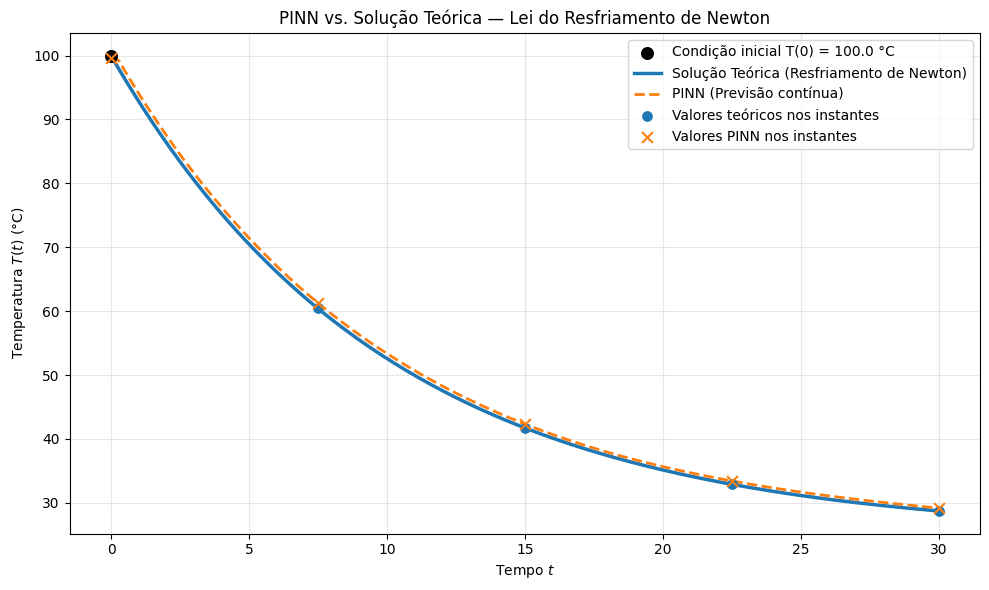

In [21]:
# 1. Plotamos o resultado comparativo atualizado
plot_all_solutions(model, t_max=t_max, T_0=T_0, k=k, T_amb=T_amb)

Podemos ver que, apesar de pequenas diferenças, a PINN modelou com sucesso o resfriamento de Newton ao longo do tempo, acompanhando bem tanto a condição inicial quanto a queda exponencial até a temperatura ambiente.

### Visualização da Convergência do Treinamento

Vamos visualizar como a previsão da PINN converge ao longo das épocas de treinamento, usando $t = 1$ (ou outro instante dentro de $[0, t_{\max}]$) como ponto de acompanhamento. Isso permite observar como a rede refina sua estimativa de temperatura à medida que o treinamento avança.

In [22]:
def plot_epoch_comparison(
    epoch_saved, saved_models, device, t_max=30.0, T_0=100.0, k=0.1, T_amb=25.0
):
  fig, ax = plt.subplots(figsize=(7, 5), dpi=100)

  # Grade temporal para visualizar a curva inteira de T(t)
  t_np = np.linspace(0.0, t_max, 200)
  t_tensor = torch.tensor(t_np, dtype=torch.float32, device=device).unsqueeze(
      1
  )

  # Solução teórica exata: T(t) = T_amb + (T_0 - T_amb) * exp(-k * t)
  T_theoretical = T_amb + (T_0 - T_amb) * np.exp(-k * t_np)

  ax.plot(
      t_np,
      T_theoretical,
      "k--",
      linewidth=2,
      label="Solução Teórica (Resfriamento de Newton)",
  )
  (line,) = ax.plot([], [], "r-", linewidth=2, label="PINN Solution")

  # Define limites fixos para evitar saltos de escala durante a animação
  y_min = min(T_0, T_amb) - 5.0
  y_max = max(T_0, T_amb) + 5.0
  ax.set_xlim(0.0, t_max)
  ax.set_ylim(y_min, y_max)

  ax.set_title("PINN vs. Solução Teórica ao Longo das Épocas")
  ax.set_xlabel("Tempo $t$")
  ax.set_ylabel("Temperatura $T(t)$ (°C)")
  ax.legend()
  ax.grid(True, alpha=0.3)

  temp_model = PINNResfriamento().to(device)

  def init():
    line.set_data([], [])
    return (line,)

  def update(epoch):
    temp_model.load_state_dict(
        {param: tensor.to(device) for param, tensor in saved_models[epoch].items()}
    )
    temp_model.eval()
    with torch.no_grad():
      T_pred = temp_model(t_tensor).cpu().numpy().squeeze()
    line.set_data(t_np, T_pred)
    ax.set_title(f"PINN vs. Solução Teórica — Época {epoch}")
    return (line,)

  ani = animation.FuncAnimation(
      fig,
      update,
      frames=epoch_saved,
      init_func=init,
      blit=True,
      interval=200,
  )

  plt.close(fig)  # Evita exibir figura estática duplicada no notebook

  return ani

In [25]:
epoch_show = [1] + list(range(10, 651, 10)) + list(range(650, 4000, 50))
anim = plot_epoch_comparison(
    epoch_show,
    saved_models,
    device,
    t_max=t_max,
    T_0=T_0,
    k=k,
    T_amb=T_amb,
)

In [26]:
# Usage example
from IPython.display import HTML
HTML(anim.to_jshtml())

## Conclusão
Parabéns!

Agora que você treinou e validou uma Rede Neural Informada por Física (PINN) para resolver uma equação diferencial ordinária (EDO) de 1ª ordem, você deu o primeiro passo na aplicação do aprendizado de máquina a problemas baseados em física. Este primeiro experimento trabalhou com a **Lei do Resfriamento de Newton** (decaimento exponencial no tempo), mas os princípios centrais — diferenciação automática (`autograd`), resíduo físico na função de perda e condição inicial — formam a base para modelos mais complexos.

Nos próximos passos da trilha, você poderá estender essas ideias para equações com derivadas de maior ordem, sistemas acoplados e equações diferenciais parciais (EDPs) no espaço e no tempo (como difusão, ondas ou dinâmica de fluidos), ajustando a arquitetura da rede, a amostragem dos pontos de colocação e os termos da função de perda.

Se você quiser se aprofundar em abordagens mais avançadas de Aprendizado de Máquina Informado por Física além das PINNs clássicas, vale explorar referências sobre arquiteturas modernas e aprendizado de operadores (como *Physics-Informed Neural Operators* / *Fourier Neural Operators* e modelos baseados em *Transformers* para equações diferenciais), aplicando esses métodos a novos problemas físicos.

Sinta-se à vontade para experimentar com diferentes valores de $k$, $T_{\text{amb}}$ e $T_0$, ou usar este notebook como ponto de partida para os próximos passos do seu repositório no GitHub!

## Autores
- Adaptação para o Passo 01 (Lei do Resfriamento de Newton) e trilha de PINNs: Vitor Hugo de Araujo Thompson
- Material base de referência (Difusão 1D): J.C. (Junxing) Chen (IBM)

## Histórico de Alterações
| Data (AAAA-MM-DD) | Versão | Alterado Por | Descrição da Alteração |
| :--- | :--- | :--- | :--- |
| 2024-08-15 | 0.1 | J.C. (Junxing) Chen | Criação do laboratório base (Difusão 1D) |
| 2026-11-22 | 1.0 | Vitor Hugo de Araujo Thompson | Adaptação para o Passo 01: Lei do Resfriamento de Newton (EDO de 1ª ordem) |